In [13]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42


In [5]:
# import the data
train = pd.read_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/data/processed/train.csv")
test  = pd.read_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/data/processed/test.csv")
X_train, y_train = train["clean_message"], train["label_num"]
X_test,  y_test  = test["clean_message"],  test["label_num"]

## TF-IDF vectorization

In [7]:

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)

# Fit on TRAIN only, then transform both (prevents data leakage)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF matrix (train):", X_train_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

TF-IDF matrix (train): (4120, 5862)
Vocabulary size: 5862


## Train and Compare Models

In [9]:
# train and compare naive, svm, lr

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
}

results, preds = [], {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    preds[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (spam)": precision_score(y_test, y_pred),
        "Recall (spam)": recall_score(y_test, y_pred),
        "F1 (spam)": f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.sort_values("F1 (spam)", ascending=False)

,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
Logistic Regression,0.9893,0.9606,0.9531,0.9569
Linear SVM,0.9884,0.9754,0.9297,0.9520
Naive Bayes,0.9690,0.9898,0.7578,0.8584


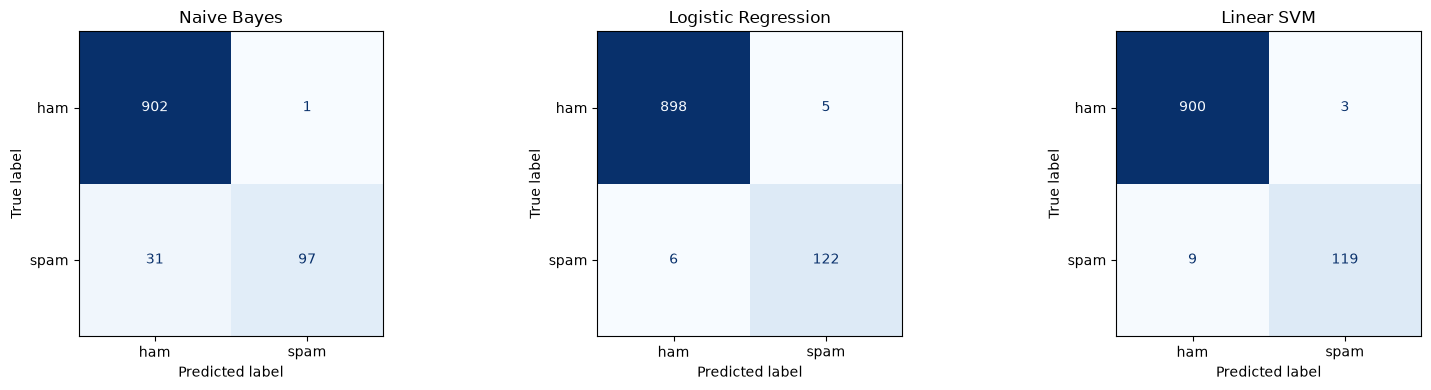

In [10]:
# Confusion matrices side by side
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (name, y_pred) in zip(ax, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["ham", "spam"], cmap="Blues", ax=a, colorbar=False
    )
    a.set_title(name)
plt.tight_layout()
plt.show()

In [11]:
# Detailed report for each model
for name, y_pred in preds.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

===== Naive Bayes =====
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       903
        spam       0.99      0.76      0.86       128

    accuracy                           0.97      1031
   macro avg       0.98      0.88      0.92      1031
weighted avg       0.97      0.97      0.97      1031

===== Logistic Regression =====
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.96      0.95      0.96       128

    accuracy                           0.99      1031
   macro avg       0.98      0.97      0.98      1031
weighted avg       0.99      0.99      0.99      1031

===== Linear SVM =====
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.93      0.95       128

    accuracy                           0.99      1031
   macro avg       0.98      0.96      0.97      

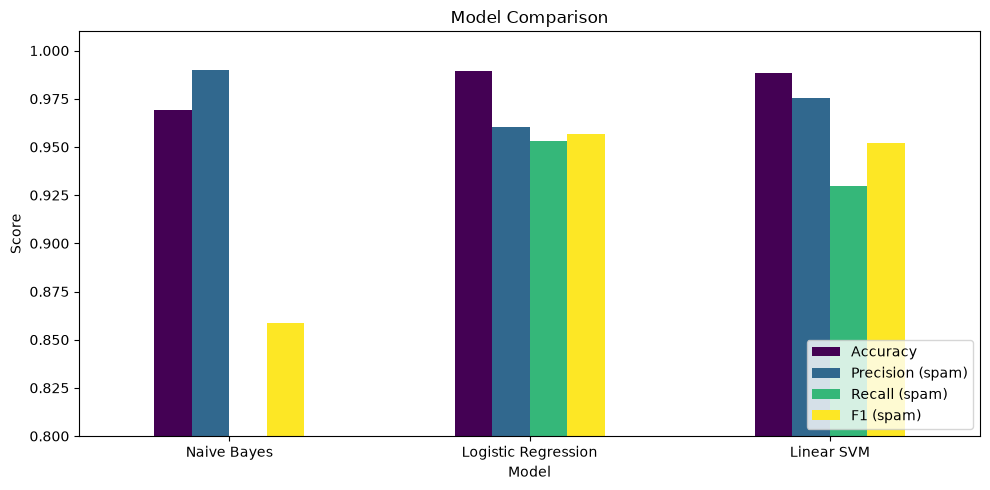

In [12]:
# Metric comparison chart
results_df.plot(kind="bar", figsize=(10, 5), ylim=(0.8, 1.01), colormap="viridis")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Cross-validation and hyperparameter tuning

In [14]:


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 9a. Cross-validated F1 for each model (vectorizer is refit inside each fold, so no leakage)
cv_rows = []
for name, model in models.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                     ("clf", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    cv_rows.append({"Model": name, "CV F1 mean": scores.mean(), "CV F1 std": scores.std()})

pd.DataFrame(cv_rows).set_index("Model").round(4)

,CV F1 mean,CV F1 std
Model,,
Naive Bayes,0.8920,0.0178
Logistic Regression,0.9139,0.0154
Linear SVM,0.9362,0.0140


In [15]:
# 9b. Grid search on the strongest candidates
pipe_svm = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)),
                     ("clf", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))])

param_svm = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2, 3],
    "clf__C": [0.1, 0.5, 1, 2, 5],
}

gs_svm = GridSearchCV(pipe_svm, param_svm, cv=cv, scoring="f1", n_jobs=-1)
gs_svm.fit(X_train, y_train)
print("Best SVM params:", gs_svm.best_params_)
print("Best SVM CV F1 :", round(gs_svm.best_score_, 4))

Best SVM params: {'clf__C': 5, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}
Best SVM CV F1 : 0.9458


In [16]:
pipe_nb = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)),
                    ("clf", MultinomialNB())])

param_nb = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2, 3],
    "clf__alpha": [0.01, 0.05, 0.1, 0.5, 1.0],
}

gs_nb = GridSearchCV(pipe_nb, param_nb, cv=cv, scoring="f1", n_jobs=-1)
gs_nb.fit(X_train, y_train)
print("Best NB params:", gs_nb.best_params_)
print("Best NB CV F1 :", round(gs_nb.best_score_, 4))

Best NB params: {'clf__alpha': 0.1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}
Best NB CV F1 : 0.9425


In [17]:
pipe_lr = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)),
                    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=RANDOM_STATE))])

param_lr = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2, 3],
    "clf__C": [0.5, 1, 5, 10, 50],
}

gs_lr = GridSearchCV(pipe_lr, param_lr, cv=cv, scoring="f1", n_jobs=-1)
gs_lr.fit(X_train, y_train)
print("Best LR params:", gs_lr.best_params_)
print("Best LR CV F1 :", round(gs_lr.best_score_, 4))

Best LR params: {'clf__C': 50, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 1)}
Best LR CV F1 : 0.947


In [ ]:
import joblibm
joblib.dump(gs_nb.best_estimator_,  "/Users/EXOTISCH TECH/Desktop/sms-spam-detector/odels/nb_tuned.pkl")
joblib.dump(gs_lr.best_estimator_,  "/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/lr_tuned.pkl")
joblib.dump(gs_svm.best_estimator_, "/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/svm_tuned.pkl")



In [20]:
pd.DataFrame({"model": ["nb", "lr", "svm"],
              "cv_f1": [gs_nb.best_score_, gs_lr.best_score_, gs_svm.best_score_]}
            ).to_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/cv_scores.csv", index=False)

In [ ]:
# review the saved cv_score
cv_scores = pd.read_csv("/Users/EXOTISCH TECH/Desktop/sms-spam-detector/models/cv_scores.csv")
cv_scores

,model,cv_f1
0,nb,0.942507
1,lr,0.946963
2,svm,0.945825
